<div style="background: linear-gradient(120deg, #3b1e54 0%, #8a2a6b 62%, #d6336c 100%); color: #ffffff; padding: 30px 34px; border-radius: 14px; margin: 4px 0 10px 0;">
<div style="font-size: 0.8em; letter-spacing: 0.16em; text-transform: uppercase; opacity: 0.85;">Statistical Methods · GSSI · Lecture 2 · 16/11</div>
<div style="font-size: 2.7em; font-weight: 800; line-height: 1.1; margin: 10px 0 8px 0;">Distributions</div>
<div style="font-size: 1.15em; opacity: 0.95;">A small zoo of distributions that describes almost everything we measure.</div>
</div>

**Reading** · G. Benato, *Statistical Methods for Astroparticle Physics* (GSSI lecture notes), chapters 2-3.

**In this lecture**

1. [Bernoulli](#s1)
2. [Binomial](#s2)
3. [Multinomial](#s3)
4. [Uniform](#s4)
5. [Exponential](#s5)
6. [Poisson](#s6)
7. [Normal (Gaussian)](#s7)
8. [Chi-squared](#s8)
9. [Theorems in statistics](#s9)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler
from scipy import stats

# --- house style: one palette for every figure ------------------------------------
PLUM, FUCHSIA, TEAL, AMBER, GREY = "#3b1e54", "#d6336c", "#0b7285", "#e8890c", "#6b7280"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "axes.prop_cycle": cycler(color=[FUCHSIA, PLUM, TEAL, AMBER]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": "#2a1a3a", "text.color": "#2a1a3a",
    "xtick.color": GREY, "ytick.color": GREY, "lines.linewidth": 2.0,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 10,
})
rng = np.random.default_rng(2026)   # fixed seed: every run gives the same figures

---
## 1. Bernoulli <a id="s1"></a>

The simplest random experiment: one extraction, two outcomes. We have $N$ balls, $r$ of them red, and the probability of extracting a red one is $p = r/N$.

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Bernoulli distribution**

$$f(k;p) = \begin{cases} p & \text{if } k = 1 \text{ (red)} \\ 1-p & \text{if } k = 0 \end{cases} \qquad\Longleftrightarrow\qquad f(k;p) = p^k\,(1-p)^{1-k}$$

Mean: $\bar{x} = \sum_{x=0}^{1} x\,f(x;p) = p$. Since $\langle x^2 \rangle = p$, the variance is $V = \langle x^2 \rangle - \bar{x}^2 = p(1-p)$.

</div>

---
## 2. Binomial <a id="s2"></a>

Now repeat the extraction $n$ times, putting the ball back each time. The number $k$ of red balls follows the **binomial** distribution: the discrete distribution of $n$ independent Bernoulli extractions with probability $p$.

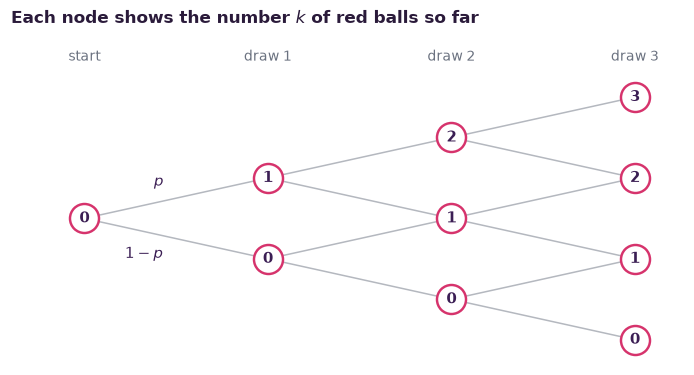

In [2]:
levels, dx, dy = 3, 1.5, 1.0
pos = {(lv, k): (lv * dx, (k - lv / 2) * dy) for lv in range(levels + 1) for k in range(lv + 1)}

fig, ax = plt.subplots(figsize=(6.2, 3.3), constrained_layout=True)
ax.axis("off")
for lv in range(levels):
    for k in range(lv + 1):
        x0, y0 = pos[(lv, k)]
        for dk in (1, 0):
            x1, y1 = pos[(lv + 1, k + dk)]
            ax.plot([x0, x1], [y0, y1], color=GREY, lw=1, alpha=0.5, zorder=1)
            if lv == 0:
                ax.text((x0 + x1) / 2 - 0.1, (y0 + y1) / 2 + (0.1 if dk else -0.1), "$p$" if dk else "$1-p$",
                        ha="right", va="bottom" if dk else "top", color=PLUM)
for (lv, k), (x, y) in pos.items():
    ax.plot(x, y, "o", ms=19, mfc="white", mec=FUCHSIA, mew=1.6, zorder=3)
    ax.text(x, y, str(k), ha="center", va="center", color=PLUM, fontweight="bold", zorder=4)
for lv in range(levels + 1):
    ax.text(lv * dx, 1.95, f"draw {lv}" if lv else "start", ha="center", color=GREY, fontsize=9)
ax.set_xlim(-0.6, levels * dx + 0.4)
ax.set_ylim(-1.8, 2.3)
ax.set_title("Each node shows the number $k$ of red balls so far", loc="left")
plt.show()

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Binomial distribution**

$$f(k;n,p) = \frac{n!}{k!\,(n-k)!}\,p^k\,(1-p)^{n-k}$$

The binomial coefficient counts the paths that lead to $k$ successes. Mean: $\bar{k} = np$. Variance: $V = np(1-p)$.

</div>

<div style="border-left: 6px solid #3b1e54; background: #f0e9f7; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**✎ Exercise**

For large $n$ the factorials overflow: the exercise asks you to compute the distribution without predefined functions.

- [Binomial](../exercises/01_distributions/ex01_binomial.ipynb)

</div>

---
## 3. Multinomial <a id="s3"></a>

Same story with more than two colors. We make $n$ extractions from a bag with balls of $m$ colors, color $i$ being extracted with probability $p_i$.

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Multinomial distribution**

$$P(k_1,\dots,k_m \,|\, n, p_1,\dots,p_m) = \frac{n!}{k_1!\cdots k_m!}\,p_1^{k_1}\cdots p_m^{k_m}$$

- average: $\bar{k}_i = n\,p_i$
- variance: $V[k_i] = n\,p_i(1-p_i)$
- covariance: $\operatorname{cov}(k_i, k_j) = -n\,p_i\,p_j \quad \forall\, i \ne j$

It is the distribution to use whenever you have a **histogram**: $n$ entries distributed in $m$ bins.

</div>

---
## 4. Uniform <a id="s4"></a>

All values between $a$ and $b$ are equally likely.

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Uniform distribution**

$$f(x) = \begin{cases} \dfrac{1}{b-a} & \text{if } a \le x \le b \\[2mm] 0 & \text{otherwise} \end{cases} \qquad \bar{x} = \frac{a+b}{2}, \qquad \sigma = \frac{b-a}{\sqrt{12}}$$

</div>

---
## 5. Exponential <a id="s5"></a>

Take $x \ge 0$ and a constant $\lambda > 0$.

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Exponential distribution**

$$f(x\,|\,\lambda) = \lambda\,e^{-\lambda x} \qquad \bar{x} = \frac{1}{\lambda}, \qquad \sigma = \frac{1}{\lambda}$$

</div>

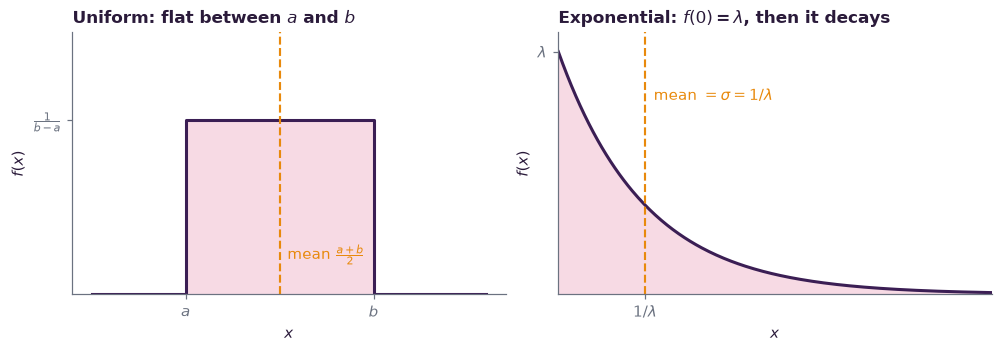

In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.1), constrained_layout=True)

# uniform
a, b = 1.0, 3.0
x = np.array([0, a, a, b, b, 4.2])
a1.plot(x, [0, 0, 1 / (b - a), 1 / (b - a), 0, 0], color=PLUM)
a1.fill_between([a, b], 0, 1 / (b - a), color=FUCHSIA, alpha=0.18, lw=0)
a1.axvline((a + b) / 2, color=AMBER, ls="--", lw=1.4)
a1.text((a + b) / 2 + 0.08, 0.1, r"mean $\frac{a+b}{2}$", color=AMBER)
a1.set(xticks=[a, b], xticklabels=["$a$", "$b$"], yticks=[1 / (b - a)], yticklabels=[r"$\frac{1}{b-a}$"],
       ylim=(0, 0.75), xlabel="$x$", ylabel="$f(x)$")
a1.set_title("Uniform: flat between $a$ and $b$", loc="left")

# exponential
lam = 1.0
x = np.linspace(0, 5, 300)
a2.plot(x, lam * np.exp(-lam * x), color=PLUM)
a2.fill_between(x, lam * np.exp(-lam * x), color=FUCHSIA, alpha=0.18, lw=0)
a2.axvline(1 / lam, color=AMBER, ls="--", lw=1.4)
a2.text(1 / lam + 0.1, 0.8, r"mean $= \sigma = 1/\lambda$", color=AMBER)
a2.set(xticks=[1 / lam], xticklabels=[r"$1/\lambda$"], yticks=[lam], yticklabels=[r"$\lambda$"],
       xlim=(0, 5), ylim=(0, 1.08), xlabel="$x$", ylabel="$f(x)$")
a2.set_title("Exponential: $f(0) = \\lambda$, then it decays", loc="left")
plt.show()

<div style="border-left: 6px solid #3b1e54; background: #f0e9f7; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**✎ Exercise**

Where does the exponential come from? From *uniform* extractions: the intervals between consecutive events are exponentially distributed.

- [Exponential from uniform](../exercises/01_distributions/ex02_exponential.ipynb)

</div>

---
## 6. Poisson <a id="s6"></a>

Take a variable $t$ uniformly distributed over $[0, \Delta t]$: a position on a pixelated detector, or the arrival time of a particle. Assume $t$ is extracted $n$ times in $\Delta t$, so the rate of extractions is $r = n/\Delta t$. Now look only at a shorter interval $\delta t \ll \Delta t$: the number $k$ of extractions that fall in it is binomial.

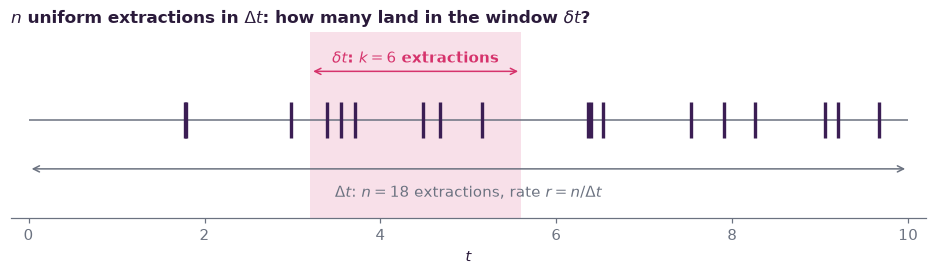

In [4]:
T, n, w0, w1 = 10.0, 18, 3.2, 5.6
pts = np.sort(rng.uniform(0, T, n))
k = int(((pts >= w0) & (pts <= w1)).sum())

fig, ax = plt.subplots(figsize=(8.4, 2.4), constrained_layout=True)
ax.hlines(0, 0, T, color=GREY, lw=1)
ax.axvspan(w0, w1, color=FUCHSIA, alpha=0.15, lw=0)
ax.plot(pts, np.zeros(n), "|", ms=24, mew=2.2, color=PLUM)
ax.annotate("", xy=(w1, 0.75), xytext=(w0, 0.75), arrowprops=dict(arrowstyle="<->", color=FUCHSIA))
ax.text((w0 + w1) / 2, 0.88, rf"$\delta t$: $k = {k}$ extractions", ha="center", color=FUCHSIA, fontweight="bold")
ax.annotate("", xy=(T, -0.75), xytext=(0, -0.75), arrowprops=dict(arrowstyle="<->", color=GREY))
ax.text(T / 2, -1.0, rf"$\Delta t$: $n = {n}$ extractions, rate $r = n/\Delta t$", ha="center", va="top", color=GREY)
ax.set(xlim=(-0.2, T + 0.2), ylim=(-1.5, 1.35), xlabel="$t$", yticks=[])
ax.set_title(r"$n$ uniform extractions in $\Delta t$: how many land in the window $\delta t$?", loc="left")
for s in ("left",):
    ax.spines[s].set_visible(False)
plt.show()

Take the limits $n \to \infty$ and $\Delta t \to \infty$, keeping the rate $r$ fixed. The expected number of extractions in $\delta t$ is $\nu = \langle k \rangle = \frac{n}{\Delta t}\,\delta t = r\,\delta t$, and

$$P(k;n,\nu) = \frac{n!}{k!\,(n-k)!}\left(\frac{\nu}{n}\right)^{k}\left(1-\frac{\nu}{n}\right)^{n-k} = \frac{\nu^k}{k!}\cdot\underbrace{\frac{n(n-1)\cdots(n-k+1)}{n^k}}_{\to\,1}\cdot\underbrace{\left(1-\frac{\nu}{n}\right)^{n}}_{\to\,e^{-\nu}}\cdot\underbrace{\left(1-\frac{\nu}{n}\right)^{-k}}_{\to\,1}$$

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Poisson distribution**

$$P(k;\nu) = \frac{\nu^k\,e^{-\nu}}{k!} \qquad \bar{k} = \nu, \qquad \sigma = \sqrt{\nu}$$

</div>

### Properties

- For large $\nu$, a Poisson distribution can be approximated with a Gaussian with $\mu = \nu$ and $\sigma = \sqrt{\nu}$.
- A binomial distribution with $p \ll 1$ can be approximated with a Poisson distribution with $\nu = pn$.
- **The sum of two Poisson variables is Poisson.** If $k_1, k_2$ are Poisson with expected values $\nu_1, \nu_2$, then $k = k_1 + k_2$ is Poisson with $\nu = \nu_1 + \nu_2$:

$$P(k;\nu_1,\nu_2) = \sum_{j=0}^{k} \frac{e^{-\nu_1}\nu_1^{\,j}}{j!}\,\frac{e^{-\nu_2}\nu_2^{\,k-j}}{(k-j)!} = \frac{e^{-(\nu_1+\nu_2)}}{k!}\underbrace{\sum_{j=0}^{k}\frac{k!}{j!\,(k-j)!}\,\nu_1^{\,j}\,\nu_2^{\,k-j}}_{(\nu_1+\nu_2)^k \text{ (binomial expansion)}} = \frac{e^{-\nu}\,\nu^k}{k!}$$

  This matters because both background and signal read by a detector are Poissonian: in a bin with $b$ background events and $s$ signal events, the sum is still a Poisson.

- **Randomly picking with probability $\varepsilon$ from a Poisson process gives again a Poisson process.** Take a Poisson variable $n$ with expected value $\nu_0$: a binomial variable $k$ with probability $\varepsilon \in [0,1]$ and sample size $n$ is Poisson with expected value $\nu = \varepsilon\,\nu_0$:

$$P(k;\nu_0,\varepsilon) = \sum_{n=0}^{\infty}\frac{e^{-\nu_0}\nu_0^{\,n}}{n!}\,\frac{n!}{k!\,(n-k)!}\,\varepsilon^k(1-\varepsilon)^{n-k} = \frac{\nu^k e^{-\nu_0}}{k!}\sum_{n=0}^{\infty}\frac{[\nu_0(1-\varepsilon)]^{n-k}}{(n-k)!} = \frac{\nu^k e^{-\nu}}{k!}$$

  This is a detector with efficiency $\varepsilon$ measuring a Poisson process: what it sees is still Poissonian.

<div style="border-left: 6px solid #3b1e54; background: #f0e9f7; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**✎ Exercise**

Is it binomial or Poisson? The exercise compares the two over a grid of $(n, p)$.

- [Poisson](../exercises/01_distributions/ex03_poisson.ipynb)

</div>

---
## 7. Normal (Gaussian) <a id="s7"></a>

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Normal distribution**

$$g(x;\mu,\sigma) = \frac{1}{\sqrt{2\pi}\,\sigma}\exp\!\left(-\frac{(x-\mu)^2}{2\sigma^2}\right), \quad x \in \mathbb{R} \qquad \text{mean } \mu,\ \text{standard deviation } \sigma$$

Standard normal ($\mu = 0$, $\sigma = 1$): $\;\phi(x) = \dfrac{1}{\sqrt{2\pi}}\,e^{-x^2/2}$

</div>

The cumulative of the standard normal, and of the normal, are

$$\Phi(x) = \frac{1}{\sqrt{2\pi}}\int_{-\infty}^{x} e^{-t^2/2}\,dt = \frac{1}{2}\left[\operatorname{erf}\!\left(\frac{x}{\sqrt{2}}\right) + 1\right] \qquad\qquad G(x;\mu,\sigma) = \frac{1}{2}\left[\operatorname{erf}\!\left(\frac{x-\mu}{\sqrt{2}\,\sigma}\right) + 1\right]$$

### Properties

If $x_1, x_2$ are **independent** Gaussian variables with means $\mu_1, \mu_2$ and standard deviations $\sigma_1, \sigma_2$, their combination $x = a x_1 + b x_2$ is Gaussian with mean and standard deviation

$$\mu = a\mu_1 + b\mu_2, \qquad \sigma = \sqrt{a^2\sigma_1^2 + b^2\sigma_2^2}$$

<div style="border-left: 6px solid #e8890c; background: #fff3dc; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**▲ Watch out**

The formula for $\sigma$ holds for independent variables: otherwise a term $2ab\,\operatorname{cov}(x_1, x_2)$ must be added under the root. And sometimes the sum of two Gaussian distributed variables is **not** a Gaussian: it is when they are jointly Gaussian.

</div>

### Multivariate normal

A multivariate normal distribution is a Gaussian in dimension $> 1$. For $\vec{x} \in \mathbb{R}^n$:

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Multivariate normal**

$$g(\vec{x}) = \frac{1}{(2\pi)^{n/2}\,|C|^{1/2}}\exp\!\left[-\frac{1}{2}(\vec{x}-\vec{\mu})^{T}\,C^{-1}\,(\vec{x}-\vec{\mu})\right], \qquad C = \begin{pmatrix} \sigma_1^2 & \rho_{12}\sigma_1\sigma_2 & \cdots \\ \rho_{12}\sigma_1\sigma_2 & \sigma_2^2 & \cdots \\ \vdots & \vdots & \ddots \end{pmatrix}$$

$C$ is the covariance matrix.

</div>

One can also forget about the covariance matrix and **rotate the system of reference**, $x' = \cos\phi\,x + \sin\phi\,y$ and $y' = -\sin\phi\,x + \cos\phi\,y$: in the new frame the Gaussian has no correlation.

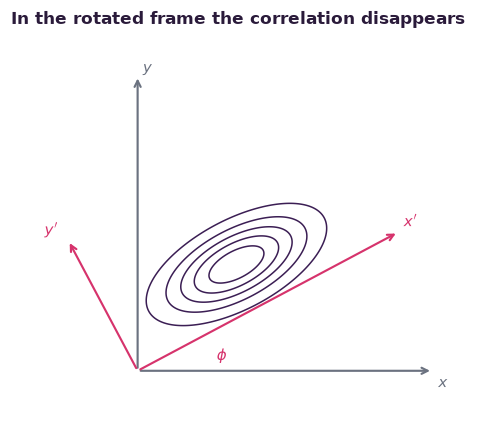

In [5]:
phi = np.deg2rad(28)
g = np.linspace(-1, 6, 320)
X, Y = np.meshgrid(g, g)
xp = np.cos(phi) * X + np.sin(phi) * Y            # coordinates in the rotated frame
yp = -np.sin(phi) * X + np.cos(phi) * Y
Z = stats.norm(2.6, 1.0).pdf(xp) * stats.norm(0.9, 0.45).pdf(yp)

fig, ax = plt.subplots(figsize=(4.4, 3.9), constrained_layout=True)
ax.contour(X, Y, Z, levels=5, colors=PLUM, linewidths=1)
L = 5.6
arrow = dict(arrowstyle="->", lw=1.4)
ax.annotate("", xy=(L, 0), xytext=(0, 0), arrowprops=dict(**arrow, color=GREY))
ax.annotate("", xy=(0, L), xytext=(0, 0), arrowprops=dict(**arrow, color=GREY))
ax.annotate("", xy=(L * np.cos(phi), L * np.sin(phi)), xytext=(0, 0), arrowprops=dict(**arrow, color=FUCHSIA))
ax.annotate("", xy=(-0.5 * L * np.sin(phi), 0.5 * L * np.cos(phi)), xytext=(0, 0), arrowprops=dict(**arrow, color=FUCHSIA))
ax.text(L + 0.1, -0.1, "$x$", color=GREY, va="top")
ax.text(0.1, L + 0.05, "$y$", color=GREY)
ax.text(L * np.cos(phi) + 0.1, L * np.sin(phi) + 0.1, "$x'$", color=FUCHSIA)
ax.text(-0.5 * L * np.sin(phi) - 0.45, 0.5 * L * np.cos(phi) + 0.1, "$y'$", color=FUCHSIA)
ax.text(1.5, 0.2, r"$\phi$", color=FUCHSIA)
ax.set(aspect="equal", xlim=(-2.4, 6.6), ylim=(-0.8, 6.4))
ax.axis("off")
ax.set_title("In the rotated frame the correlation disappears", loc="left")
plt.show()

---
## 8. Chi-squared <a id="s8"></a>

A $\chi^2$ random variable with $n$ degrees of freedom (DOF) is the sum of the **squares** of $n$ independent standard normal variables.

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Chi-squared distribution**

$$f(\chi^2;n) = \frac{2^{-n/2}}{\Gamma(n/2)}\,\chi^{n-2}\,e^{-\chi^2/2} \qquad \langle\chi^2\rangle = n, \qquad \sigma = \sqrt{2n}$$

Here $\chi^{n-2} = (\chi^2)^{n/2-1}$, and $\Gamma$ is the gamma function, the extension of the factorial: $\Gamma(n) = (n-1)!$ for integers.

</div>

<div style="border-left: 6px solid #3b1e54; background: #f0e9f7; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**✎ Exercise**

Build it yourself: generate standard normal numbers, square them, add them up.

- [$\chi^2$ distribution](../exercises/01_distributions/ex04_chi2.ipynb)

</div>

---
## 9. Theorems in statistics <a id="s9"></a>

*Monte Carlo methods begin here.* Three results explain why simulating and averaging works.

### Convergence in probability

The sequence $\{x_1, \dots, x_n\}$ **converges in probability** to $\bar{x}$ if for all $\epsilon > 0$ and $\eta > 0$ a value $n_0$ can be found such that

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Convergence in probability**

$$P\big(|x_n - \bar{x}| > \epsilon\big) < \eta \qquad \forall\, n \ge n_0$$

</div>

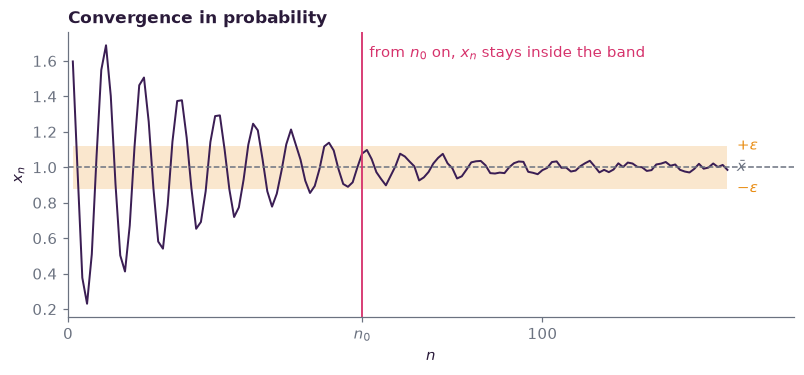

In [6]:
rng2 = np.random.default_rng(2026)
n = np.arange(1, 140)
x_n = 1 + 0.9 * np.exp(-n / 30) * np.cos(0.8 * n) + rng2.normal(0, 0.012, n.size)
eps, n0 = 0.12, 62

fig, ax = plt.subplots(figsize=(7.2, 3.3), constrained_layout=True)
ax.fill_between(n, 1 - eps, 1 + eps, color=AMBER, alpha=0.2, lw=0)
ax.plot(n, x_n, color=PLUM, lw=1.3)
ax.axhline(1, color=GREY, ls="--", lw=1)
ax.axvline(n0, color=FUCHSIA, lw=1.2)
ax.text(n0 + 1.5, 1.62, r"from $n_0$ on, $x_n$ stays inside the band", color=FUCHSIA)
ax.text(n[-1] + 2, 1, r"$\bar{x}$", va="center", color=GREY)
ax.text(n[-1] + 2, 1 + eps, r"$+\epsilon$", va="center", color=AMBER)
ax.text(n[-1] + 2, 1 - eps, r"$-\epsilon$", va="center", color=AMBER)
ax.set(xlim=(0, n[-1] + 14), xlabel="$n$", ylabel="$x_n$", xticks=[0, n0, 100], xticklabels=["0", "$n_0$", "100"])
ax.set_title("Convergence in probability", loc="left")
plt.show()

### Law of large numbers

Take a random variable $x$ with some PDF and standard deviation $\sigma$, and repeat the measurement $n$ times. The average is $\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$.

- **Weak law.** If the parent mean $\mu$ exists (the true value is defined) and $\lim_{n\to\infty}\left[\frac{1}{n^2}\sum_i \sigma_i^2\right] = 0$, then $\bar{x}$ converges to $\mu$ in quadratic mean: $\lim_{n\to\infty} E\big[(\bar{x}-\mu)^2\big] = 0$.
- **Strong law.** If $\lim_{n\to\infty}\left[\sum_i \left(\sigma_i/i\right)^2\right]$ is finite, then $P\big(\lim_{n\to\infty}\bar{x} = \mu\big) = 1$: $\bar{x}$ converges *almost certainly* to $\mu$.

**Take-home:** if the parent mean $\mu$ exists, the more you measure, the closer the sample mean $\bar{x}$ gets to $\mu$.

### Central limit theorem

Take a sequence of independent variables $x_i$ with means $\mu_i$ and standard deviations $\sigma_i$. The sum $s = \sum_i x_i$ has mean $\mu = \sum_i \mu_i$ and variance $\sigma^2 = \sum_i \sigma_i^2$. The central limit theorem states that

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Central limit theorem**

$$\lim_{n\to\infty}\;\frac{s - \sum_{i=1}^{n}\mu_i}{\sqrt{\sum_{i=1}^{n}\sigma_i^2}} = \text{Gauss}(0, 1)$$

In other words: the sum of $n$ independent random variables tends to a Gaussian, whatever the distribution of the single variables (the convergence is in distribution).

</div>

<div style="border-left: 6px solid #3b1e54; background: #f0e9f7; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**✎ Exercise**

Turn the theorem into a (rather inefficient) Gaussian random number generator.

- [Central limit theorem for Gaussian random number generator](../exercises/02_monte_carlo/ex01_gaussian_generator.ipynb)

</div>

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**★ What to remember**

- **Bernoulli → binomial → multinomial:** one trial, $n$ trials, $n$ trials with $m$ outcomes. Use the multinomial for histograms.
- **Uniform and exponential** are linked: intervals between uniform events are exponential.
- **Poisson** is the binomial in the limit of many trials with a small success probability. It is closed under sums and under random picking, which is why detectors keep seeing Poisson statistics.
- **Gaussian:** a sum of independent Gaussians is Gaussian (with $\sigma^2 = \sum a_i^2\sigma_i^2$). $\chi^2$ is a sum of squared standard normals.
- **The limit theorems:** the sample mean converges to the parent mean (LLN) and sums become Gaussian (CLT).

</div>